# Surrogate Gradients: Basics

A spiking neuron emits a spike when its membrane potential crosses a threshold, $s = H(V - V_{th})$. The step function $H$ has derivative zero everywhere except at the threshold, so backpropagation through spikes yields no learning signal. **Surrogate gradients** keep the exact step in the forward pass and replace its derivative in the backward pass by a smooth, localized function $\sigma'(x)$:

$$\text{forward: } s = H(x), \qquad \text{backward: } \frac{\partial s}{\partial x} := \sigma'(x), \qquad x = V - V_{th}.$$

This notebook covers:

1. using a surrogate (class and functional forms) and what its derivatives are;
2. the 18 built-in surrogates and how their gradients differ;
3. the steepness parameter;
4. gradients through time in a leaky integrate-and-fire (LIF) neuron, and the role of the reset;
5. a first optimization through spikes.

## 1. Using a Surrogate

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools.surrogate as surrogate

jax.config.update("jax_enable_x64", True)

Each surrogate is a class whose instances are called on $x = V - V_{th}$; every class has a functional twin taking the parameters as arguments. The forward output is always exactly 0 or 1:

In [2]:
sg = surrogate.Sigmoid(alpha=4.0)
x = jnp.array([-1.0, -0.1, 0.0, 0.1, 1.0])

print("forward (class):     ", sg(x))
print("forward (functional):", surrogate.sigmoid(x, alpha=4.0))
print("jax.grad of a spike: ", jax.vmap(jax.grad(sg))(x))
print("sg.surrogate_grad(x):", sg.surrogate_grad(x))

forward (class):      [0. 0. 1. 1. 1.]
forward (functional): [0. 0. 1. 1. 1.]
jax.grad of a spike:  [0.07065082 0.96104298 1.         0.96104298 0.07065082]
sg.surrogate_grad(x): [0.07065082 0.96104298 1.         0.96104298 0.07065082]


Differentiating a spike with respect to its input gives `surrogate_grad`. Two more methods are useful for analysis:

- `surrogate_grad(x)` is the function $\sigma'(x)$ used in the backward pass;
- `surrogate_fun(x)` is a smooth function $\sigma(x)$ whose derivative is $\sigma'$, defined for most (not all) surrogates and used only for plotting.

The spike does **not** depend on the surrogate's parameters, so its derivative with respect to them is zero; the parameters act only through the gradients they produce (see the third notebook for how to tune them):

In [3]:
print("d spike / d alpha            :", jax.grad(lambda a: surrogate.sigmoid(jnp.array(0.3), alpha=a))(4.0))
print("d (d spike / d x) / d alpha  :", jax.grad(lambda a: jax.grad(surrogate.sigmoid)(jnp.array(0.3), a))(4.0))

d spike / d alpha            : 0.0
d (d spike / d x) / d alpha  : 0.06324868186193615


The input must be a plain, dimensionless array: `brainunit` quantities are not accepted. With physical units, subtract the threshold and divide by a voltage scale, which then acts as the width of the surrogate in volts, e.g. `sg((V - V_th) / (1 * u.mV))`.

## 2. The Built-in Surrogates

All surrogates shown with their default parameters. The table below lists three properties that matter for training:

- **peak**: the largest gradient, at or near the threshold;
- **mass** $\int \sigma'(x)\,dx$: the total gradient a neuron passes on as its potential sweeps across the threshold. A surrogate that is the derivative of a function going from 0 to 1 has mass 1;
- **support**: where the gradient is non-zero. Outside it, a neuron passes no gradient at all.

surrogate                  peak  mass on [-50, 50]   support (|grad| > 1e-6)


Sigmoid                   1.000              1.000   [-3.80, 3.80]


SoftSign                  0.500              0.980   unbounded
Arctan                    0.500              0.992   unbounded


ERF                       0.564              1.000   [-3.64, 3.64]
PiecewiseQuadratic        1.000              1.000   [-1.00, 1.00]
PiecewiseExp              0.500              1.000   [-13.12, 13.12]


PiecewiseLeakyRelu        0.500              1.980   unbounded
LeakyRelu                 1.000             55.000   unbounded


LogTailedRelu             1.000              4.912   [0.00, 50.00]
ReluGrad                  0.300              0.300   [-1.00, 1.00]


GaussianGrad              0.399              0.500   [-2.54, 2.54]
InvSquareGrad             1.000              0.020   [-9.99, 9.99]


MultiGaussianGrad         0.439              0.425   [-13.51, 13.51]
SquarewaveFourierSeries   1.000              0.849   unbounded


S2NN                      1.000              4.432   [-3.80, 50.00]
QPseudoSpike              1.000              2.913   unbounded
SlayerGrad                1.000              2.000   [-13.82, 13.82]
NonzeroSignLog            1.000              7.864   unbounded


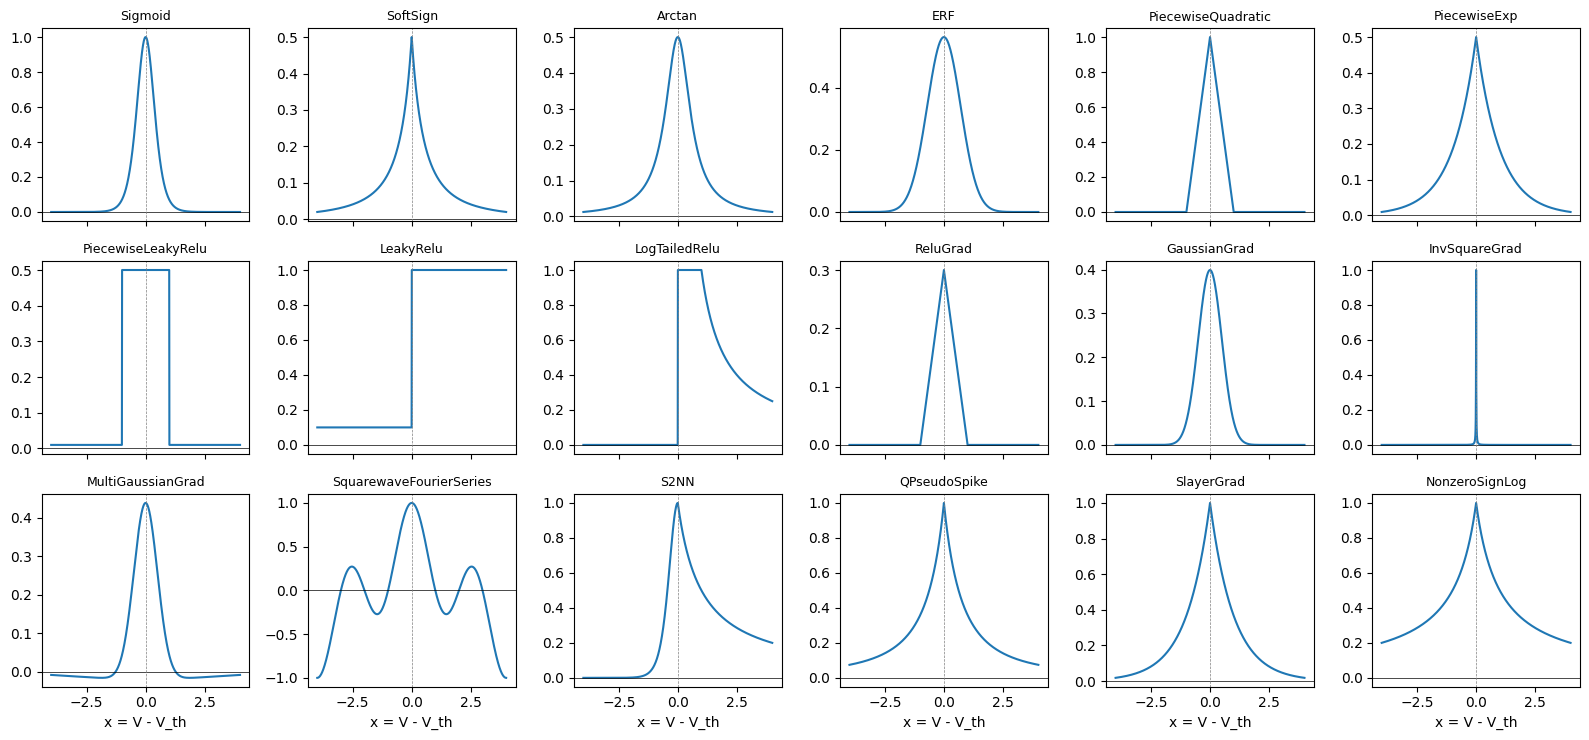

In [4]:
names = ["Sigmoid", "SoftSign", "Arctan", "ERF", "PiecewiseQuadratic", "PiecewiseExp", "PiecewiseLeakyRelu",
         "LeakyRelu", "LogTailedRelu", "ReluGrad", "GaussianGrad", "InvSquareGrad", "MultiGaussianGrad",
         "SquarewaveFourierSeries", "S2NN", "QPseudoSpike", "SlayerGrad", "NonzeroSignLog"]
xs = jnp.linspace(-4, 4, 2001)
x_wide = jnp.linspace(-50, 50, 1_000_001)

fig, axes = plt.subplots(3, 6, figsize=(16, 7.5), sharex=True)
print(f"{'surrogate':24s} {'peak':>6s} {'mass on [-50, 50]':>18s}   support (|grad| > 1e-6)")
for ax, name in zip(axes.flat, names):
    sg = getattr(surrogate, name)()
    ax.plot(xs, sg.surrogate_grad(xs))
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="gray", lw=0.5, ls="--")
    ax.set_title(name, fontsize=9)
    g = np.asarray(sg.surrogate_grad(x_wide))
    nz = np.asarray(x_wide)[np.abs(g) > 1e-6]
    support = f"[{nz.min():.2f}, {nz.max():.2f}]" if nz.max() < 49 or nz.min() > -49 else "unbounded"
    print(f"{name:24s} {g.max():6.3f} {np.trapezoid(g, np.asarray(x_wide)):18.3f}   {support}")
for ax in axes[-1]:
    ax.set_xlabel("x = V - V_th")
plt.tight_layout(); plt.show()

The surrogates fall into a few groups:

- **localized, mass ≈ 1** (`Sigmoid`, `ERF`, `PiecewiseQuadratic`, `PiecewiseExp`, and nearly `SoftSign`, `Arctan`): derivatives of smooth step approximations; they differ in shape and tail length;
- **localized, other mass** (`ReluGrad` 0.3, `GaussianGrad` 0.5, `MultiGaussianGrad` 0.43, `SlayerGrad` 2, `InvSquareGrad` 0.02 at its default `alpha=100`): gradient-only surrogates without `surrogate_fun`; their scale is a free parameter;
- **non-localized** (`LeakyRelu`, `PiecewiseLeakyRelu`, `LogTailedRelu`, `S2NN`, `QPseudoSpike`, `NonzeroSignLog`): heavy or constant tails, so neurons far from threshold keep receiving gradient. `LeakyRelu` passes 0.1 below and 1 above threshold at any distance; `LogTailedRelu` (default `alpha=0`) and `S2NN` pass essentially nothing below threshold but a slowly decaying gradient above it;
- **sign-changing**: `MultiGaussianGrad` has small negative side lobes by design, and `SquarewaveFourierSeries` oscillates between $-1$ and $1$ (it differentiates a truncated Fourier series of a periodic square wave).

Since the gradient flowing back through a spike is proportional to $\sigma'$, surrogates with different mass are **not interchangeable at a fixed learning rate**: switching from `Sigmoid` to `InvSquareGrad` shrinks the gradient through every spike by about 50 times.

## 3. Steepness

Most surrogates have a steepness parameter. For `Sigmoid`, $\sigma(x) = 1/(1 + e^{-\alpha x})$, so the gradient $\sigma'(x) = \alpha\,\sigma(x)(1 - \sigma(x))$ has peak $\alpha/4$, a width proportional to $1/\alpha$, and mass 1 for every $\alpha$: steepening makes the gradient taller and narrower.

alpha =  1: peak  0.25 (alpha/4 =  0.25), mass 1.000
alpha =  2: peak  0.50 (alpha/4 =  0.50), mass 1.000
alpha =  4: peak  1.00 (alpha/4 =  1.00), mass 1.000
alpha =  8: peak  2.00 (alpha/4 =  2.00), mass 1.000
alpha = 16: peak  4.00 (alpha/4 =  4.00), mass 1.000


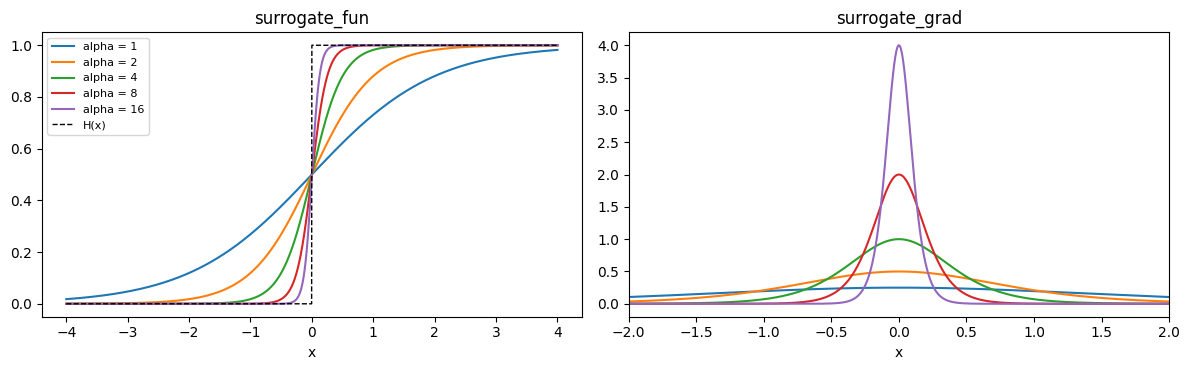

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a in [1, 2, 4, 8, 16]:
    sg = surrogate.Sigmoid(alpha=a)
    ax[0].plot(xs, sg.surrogate_fun(xs), label=f"alpha = {a}")
    ax[1].plot(xs, sg.surrogate_grad(xs), label=f"alpha = {a}")
    g = np.asarray(sg.surrogate_grad(x_wide))
    print(f"alpha = {a:2d}: peak {g.max():5.2f} (alpha/4 = {a / 4:5.2f}), mass {np.trapezoid(g, np.asarray(x_wide)):.3f}")
ax[0].plot(xs, xs >= 0, "k--", lw=1, label="H(x)"); ax[0].set_title("surrogate_fun"); ax[0].legend(fontsize=8)
ax[1].set_title("surrogate_grad"); ax[1].set_xlim(-2, 2)
for a_ in ax: a_.set_xlabel("x")
plt.tight_layout(); plt.show()

## 4. Gradients Through Time in a LIF Neuron

A LIF neuron with membrane time constant $\tau = 20$ ms, threshold 1 and a constant input $I$:

$$v_{t+1} = v_t + \frac{\Delta t}{\tau}(-v_t + I), \qquad s_t = H(v_{t+1} - 1), \qquad v_{t+1} \leftarrow v_{t+1} - s_t.$$

It fires regularly for $I > 1$, with rate $r(I) = 1 / \big(\tau \ln \frac{I}{I - 1}\big)$. The number of spikes in a trial, $N(I)$, is a staircase in $I$: its true derivative is zero almost everywhere. What does the surrogate gradient $dN/dI$ compute? We compare it with the slope of the rate curve, $T\,dr/dI$, the change in spike count per unit input that the staircase follows on average.

A modelling choice matters here: the **reset** $v \leftarrow v - s$ also involves the spike. Many implementations stop the gradient through the reset ("detach the reset"); we compare both.

surrogate              reset     dN/dI at I = 1.5, 2, 3      (slope of T r(I): [55.2 52.  50.7])


Sigmoid(1)             attached  [46.2 46.2 46.2]
Sigmoid(1)             detached  [464.3 462.2 461.4]


Sigmoid(4)             attached  [48.5 48.5 48.7]
Sigmoid(4)             detached  [1183.  1129.3 1106.2]


Sigmoid(16)            attached  [42.4 46.1 39.5]
Sigmoid(16)            detached  [1763.8 1594.  1545.5]


PiecewiseQuadratic     attached  [48.8 48.7 48.9]
PiecewiseQuadratic     detached  [1200.3 1154.9 1137.7]


ReluGrad               attached  [44.4 44.3 44.6]
ReluGrad               detached  [360.1 346.5 341.3]


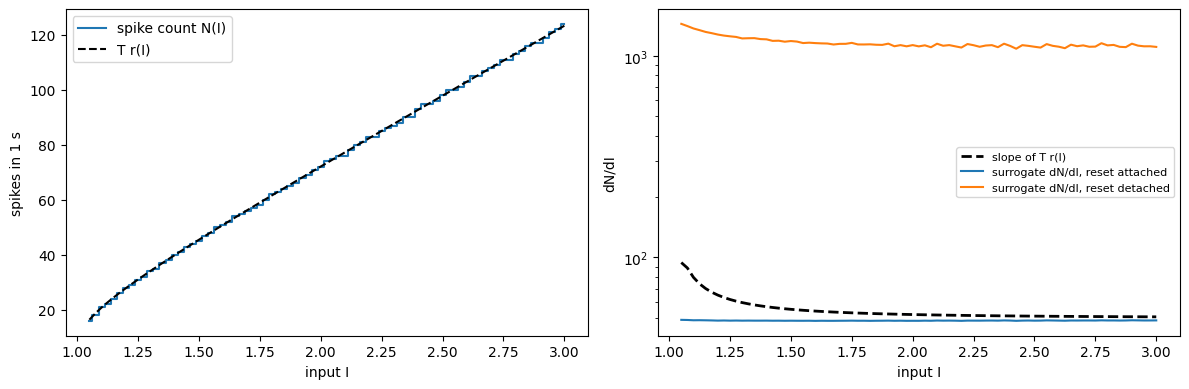

In [6]:
tau, dt, T = 20.0, 0.5, 1000.0   # ms
n_steps = int(T / dt)

def spike_count(I, sg, detach_reset=False):
    def step(v, _):
        v = v + dt / tau * (-v + I)
        s = sg(v - 1.0)
        v = v - (jax.lax.stop_gradient(s) if detach_reset else s)
        return v, s
    _, spikes = jax.lax.scan(step, jnp.asarray(0.0), None, length=n_steps)
    return spikes.sum()

currents = jnp.linspace(1.05, 3.0, 79)
rate = lambda I: 1.0 / (tau * np.log(I / (I - 1.0)))   # spikes per ms
true_slope = np.gradient(T * rate(np.asarray(currents)), np.asarray(currents))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts = jax.vmap(lambda I: spike_count(I, surrogate.Sigmoid(4.0)))(currents)
ax[0].step(currents, counts, where="mid", label="spike count N(I)")
ax[0].plot(currents, T * rate(np.asarray(currents)), "k--", label="T r(I)")
ax[0].set_xlabel("input I"); ax[0].set_ylabel("spikes in 1 s"); ax[0].legend()

ax[1].plot(currents, true_slope, "k--", lw=2, label="slope of T r(I)")
print(f"{'surrogate':22s} {'reset':9s} dN/dI at I = 1.5, 2, 3      (slope of T r(I): {np.round(np.interp([1.5, 2, 3], currents, true_slope), 1)})")
for name, sg in [("Sigmoid(1)", surrogate.Sigmoid(1.0)), ("Sigmoid(4)", surrogate.Sigmoid(4.0)),
                 ("Sigmoid(16)", surrogate.Sigmoid(16.0)), ("PiecewiseQuadratic", surrogate.PiecewiseQuadratic()),
                 ("ReluGrad", surrogate.ReluGrad())]:
    for detach in [False, True]:
        g = np.asarray(jax.vmap(jax.grad(lambda I: spike_count(I, sg, detach)))(currents))
        print(f"{name:22s} {'detached' if detach else 'attached':9s} {np.round(np.interp([1.5, 2, 3], currents, g), 1)}")
        if name == "Sigmoid(4)":
            ax[1].plot(currents, g, label=f"surrogate dN/dI, reset {'detached' if detach else 'attached'}")
ax[1].set_yscale("log"); ax[1].set_xlabel("input I"); ax[1].set_ylabel("dN/dI"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- With the gradient flowing through the reset (**attached**), $dN/dI$ is close to the true slope for all surrogates: about 46–49 against 51–55 spikes per unit input. The reason is that the subtractive reset makes the spike count telescope: summed over a trial, the reset removes one threshold per spike, so $N \approx (\text{integrated drive} - v_T)$, and the surrogate cancels out. What remains is roughly $T/\tau = 50$, the slope of a non-leaky integrator; it misses the steep rise of the LIF rate curve near rheobase ($I \to 1$).
- With a **detached** reset, the gradient is 7 to 35 times too large and depends strongly on the surrogate and its steepness: each spike contributes $\sigma'$ without the compensating reset.

Neither choice is "correct" for training, and detaching is popular because it avoids a problem shown in the third notebook (exploding gradients for steep surrogates). The point is that the reset is part of the computational graph, and how you treat it changes the gradient more than the choice of surrogate.

## 5. A First Optimization Through Spikes

With a gradient for the spike count, plain gradient descent can adjust the input current until the neuron emits a target number of spikes, although the count itself is a staircase:

In [7]:
target = 25.0
loss = lambda I: (spike_count(I, surrogate.Sigmoid(4.0)) - target) ** 2
value_and_grad = jax.jit(jax.value_and_grad(loss))

I = jnp.asarray(2.0)
for it in range(25):
    l, g = value_and_grad(I)
    if it % 4 == 0:
        print(f"step {it:2d}: I = {float(I):.4f}, spikes = {float(spike_count(I, surrogate.Sigmoid(4.0))):3.0f}")
    I = I - 5e-5 * g
print(f"final:   I = {float(I):.4f}, spikes = {float(spike_count(I, surrogate.Sigmoid(4.0))):3.0f}, theory: I with T r(I) = {target:g} is "
      f"{1 / (1 - np.exp(-T / (tau * target))):.4f}")

step  0: I = 2.0000, spikes =  72
step  4: I = 1.3847, spikes =  39
step  8: I = 1.2101, spikes =  28
step 12: I = 1.1711, spikes =  26
step 16: I = 1.1663, spikes =  25


step 20: I = 1.1663, spikes =  25
step 24: I = 1.1663, spikes =  25
final:   I = 1.1663, spikes =  25, theory: I with T r(I) = 25 is 1.1565


The count reaches the target although the loss landscape is a staircase. The final current differs slightly from the continuous-time prediction because of the discrete time step; any current within the stair of 25 spikes is a solution, and the loss (and the gradient) is exactly zero there.

## Summary

- Call a surrogate on $x = V - V_{th}$ (dimensionless). The forward pass is the exact step; `jax.grad` with respect to $x$ returns `surrogate_grad(x)`; derivatives with respect to the surrogate's own parameters are 0.
- Surrogates differ in peak, mass and support. Mass sets the overall gradient scale and interacts with the learning rate; finite support means neurons far from threshold receive no gradient.
- Steepness trades peak height against width (for `Sigmoid`: peak $\alpha/4$, mass 1).
- Through time, the reset is part of the computation. With the gradient flowing through a subtractive reset, the surrogate gradient of a spike count closely tracks the slope of the true rate curve, nearly independently of the surrogate; detaching the reset inflates it.